In [1]:
# Experiment to test the performance of different IP forward models from MPA and Cole  

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import torch

from anemone.experiment import *
from anemone.forwards import *
from anemone.inversion import SmoothModelColeCole, FewLayerColeCole

In [2]:
tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([ButterworthFilter(2.4e5,1),
                         ButterworthFilter(6.2e5,1),
                         ButterworthFilter(4.5e5,1)])

In [3]:
times = torch.logspace(-5,-3, 32)
fwrTD = Forward(tx, rx,times,filterfunc=recfilter, waveform=waveform)



frqs = torch.logspace(3, 6, 51)
fwrFD = ForwardFD(tx,rx, frqs, filterfunc=recfilter)

c:\users\au653994\onedrive - aarhus universitet\documents\phd\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [4]:
second_layer_rhos = torch.tensor([1000, 100, 10], dtype=torch.double)
Thickness = torch.tensor([30], dtype= torch.double)


rho_values= torch.logspace(start=torch.log10(torch.tensor(10)), end=torch.log10(torch.tensor(1000)), steps=11, dtype=torch.double)

cmap = cm.get_cmap('rainbow')
norm = mcolors.Normalize(vmin=float(rho_values.min()), vmax=float(rho_values.max()))
sm = cm.ScalarMappable(cmap=cmap, norm=norm)

C:\Users\au653994\AppData\Local\Temp\ipykernel_15676\4282793349.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow')


hankel coefficients didnt converge
hankel coefficients didnt converge


c:\users\au653994\onedrive - aarhus universitet\documents\phd\anemone\src\anemone\experiment\experiment.py:274: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\TensorShape.cpp:3687.)
  return HR.T.squeeze()


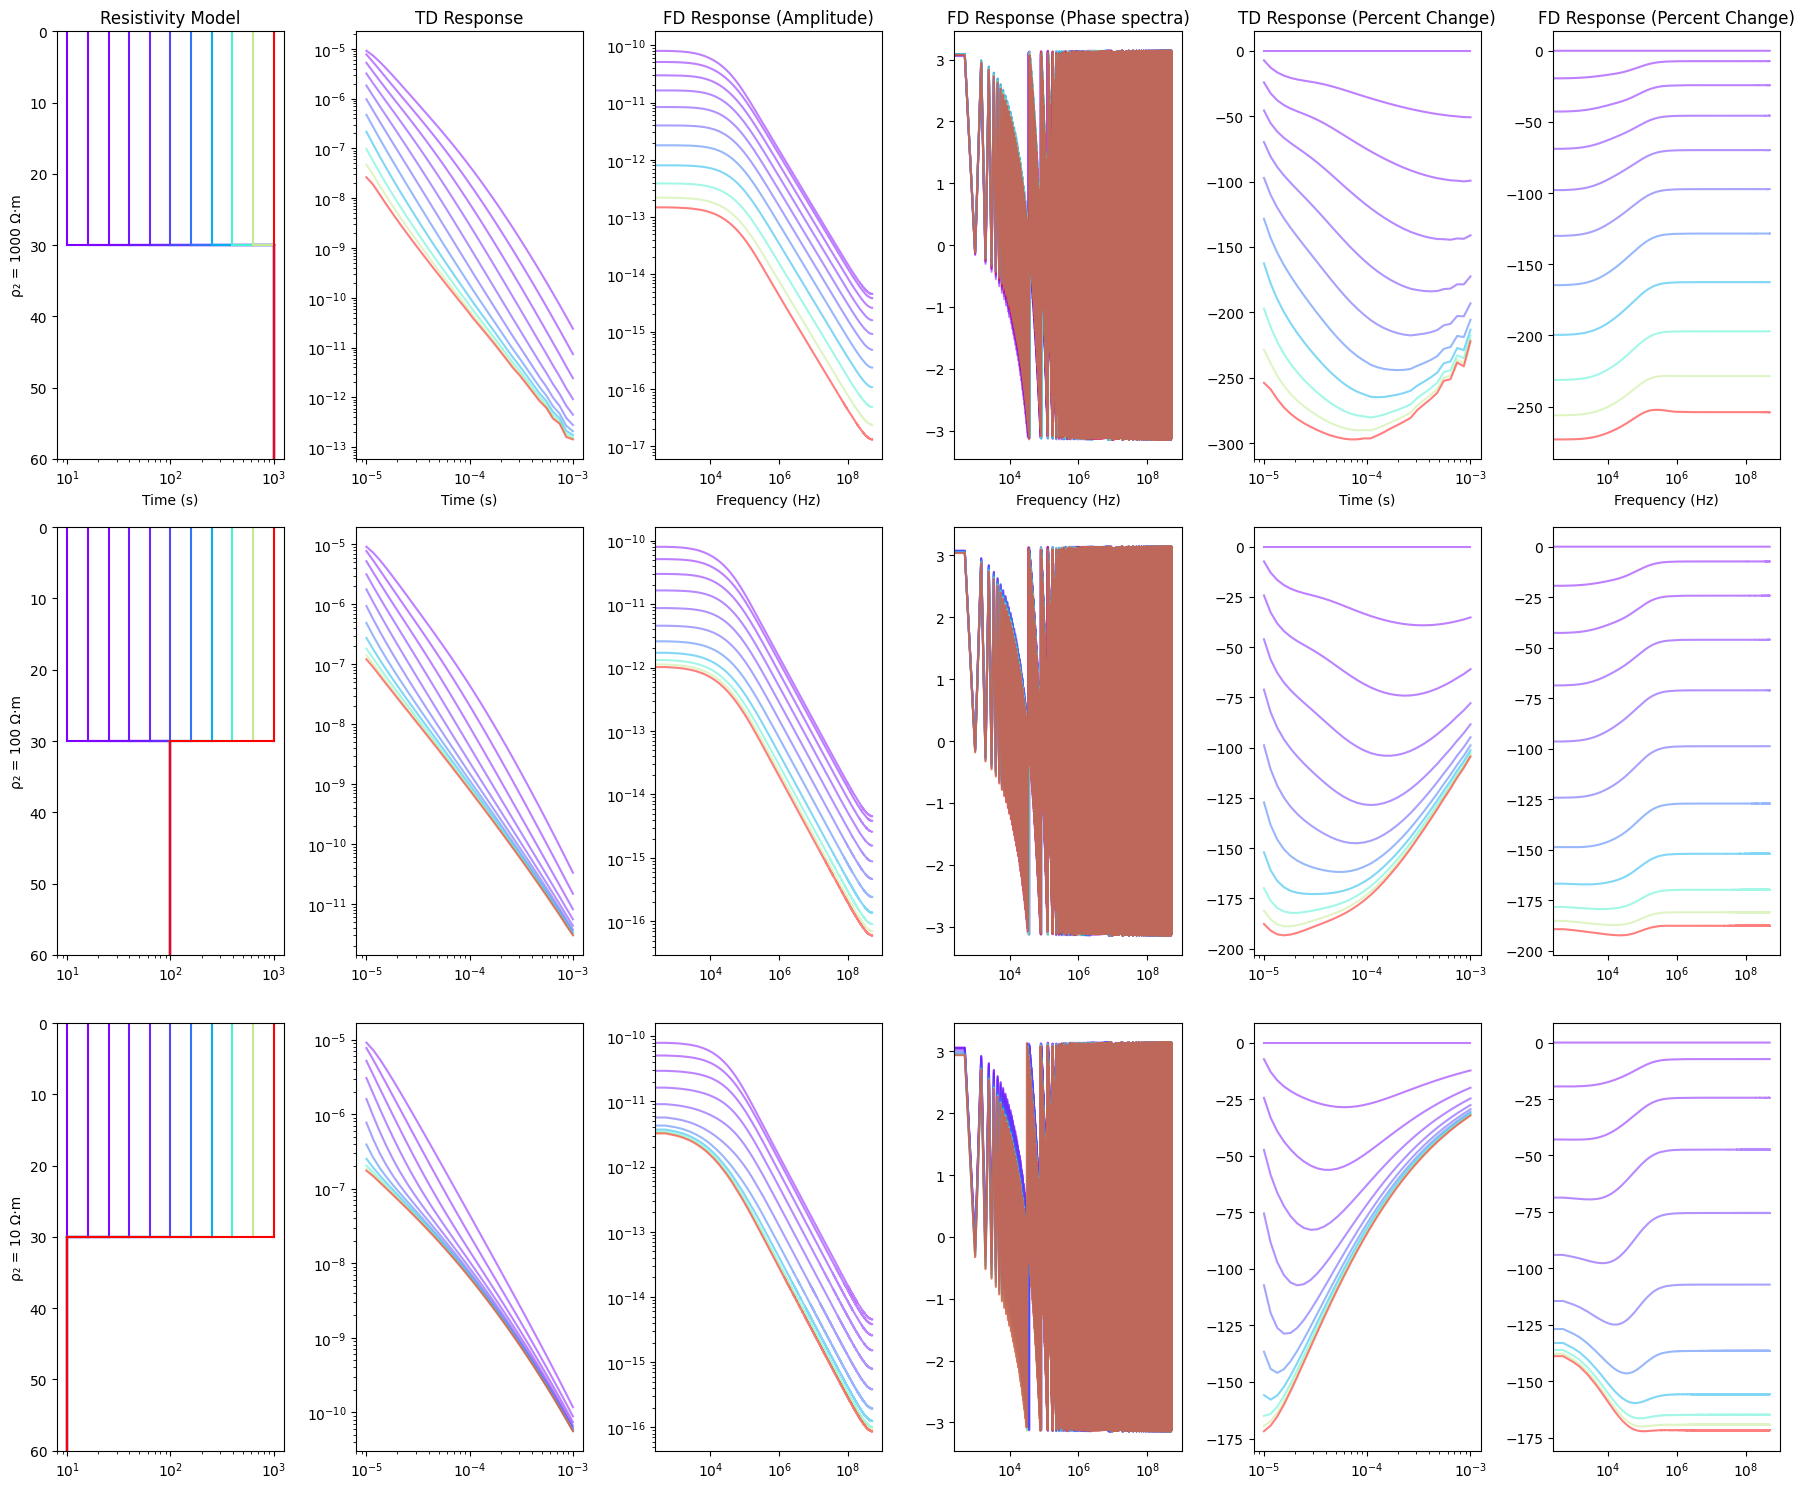

In [5]:
z0 = 0.0
z1 = Thickness[0].item()
z2 = 100.0 # Bottom truncation 


sampling_rate = 1e-9
times2 = torch.arange(times.min(), times.max(), sampling_rate)
fwrTD2 = Forward(tx, rx, times2, filterfunc=recfilter, waveform=waveform)
dt2 = times2[1] - times2[0]
dead_time = times.min() + times.max()
times2_pulseinterval = torch.arange(0, dead_time, sampling_rate)
dbdt2_pulseinterval = np.zeros_like(times2_pulseinterval)


n_models = len(second_layer_rhos)

fig, axs = plt.subplots(n_models,6, figsize=(18, 5*n_models))

for i, rho2 in enumerate(second_layer_rhos):

    rho_ref= torch.tensor([rho_values[0].item(), rho2.item()], dtype=torch.double)
    #rho_ref= torch.tensor([rho2.item(), rho_values[0].item()], dtype=torch.double) # First layer fixed

    dbdt_ref = fwrTD(rho_ref, Thickness)

    dbdt2_ref = fwrTD2(rho_ref, Thickness).real
    dbdt2_fft_input_ref = torch.cat((torch.tensor(dbdt2_pulseinterval), dbdt2_ref))
    dbdf_ref = torch.fft.fft(dbdt2_fft_input_ref) * dt2

    for rho0 in rho_values:

        color = cmap(norm(rho0.item()))

        rho = torch.tensor([rho0.item(), rho2.item()], dtype=torch.double)
        #rho = torch.tensor([ rho2.item(), rho0.item()], dtype=torch.double) # First layer fixed

        dbdt = fwrTD(rho, Thickness)
        sampling_rate = 1e-9  # 1 ns
        times2 = torch.arange(times.min(), times.max(), sampling_rate)
        fwrTD2 = Forward(tx, rx, times2, filterfunc=recfilter, waveform=waveform)

        dbdt2 = fwrTD2(rho, Thickness).real
        dt2 = times2[1] - times2[0]
        n = len(times2)

        # Create full zero-padded signal for FFT from 0 to 2*tmax
        dead_time = times.min() + times.max()
        times2_pulseinterval = torch.arange(0, dead_time, sampling_rate)
        dbdt2_pulseinterval = np.zeros_like(times2_pulseinterval)
        dbdt2_fft_input = torch.cat((torch.tensor(dbdt2_pulseinterval), dbdt2))

        # FFT and frequency axis
        dbdf_fft = torch.fft.fft(dbdt2_fft_input) * dt2
        frqs2 = torch.fft.fftfreq(len(dbdf_fft), float(dt2))

        # Use only positive frequencies for plotting
        N = len(frqs2) // 2
        frqs_plot = frqs2[:N]
        dbdf_plot = dbdf_fft[:N]


        axs[i, 1].loglog(times, dbdt, color=color, linestyle = '-',alpha=0.5)
        axs[i, 1].plot(times, -dbdt, color=color, linestyle = '-',alpha=0.5)
        axs[i, 2].loglog(frqs_plot, torch.abs(dbdf_plot), color=color, linestyle='-', alpha=0.5)
        axs[i, 3].semilogx(frqs_plot, torch.angle(dbdf_plot), color=color, linestyle='-', alpha=0.5)

        
        #pct_change_dbdt = ((dbdt - dbdt_ref) / dbdt_ref) * 100
        #pct_change_dbdf = ((dbdf - dbdf_ref) / dbdf_ref) * 100

        pct_change_dbdt = 100 * (torch.log10(torch.abs(dbdt)) - torch.log10(torch.abs(dbdt_ref)))
        pct_change_dbdf = 100 * (torch.log10(torch.abs(dbdf_plot)) - torch.log10(torch.abs(dbdf_ref[:N])))

        axs[i,4].semilogx(times, pct_change_dbdt, color=color, linestyle = '-', alpha=0.5)
        axs[i, 5].semilogx(frqs_plot, pct_change_dbdf, color=color, linestyle='-', alpha=0.5)

        # Plot the reference model 

        axs[i,0].semilogx([rho[0].item(), rho[0].item()], [z0, z1], color=color, linestyle='-')
        axs[i,0].semilogx([rho[0].item(), rho[1].item()], [z1, z1], color=color, linestyle='-')
        axs[i,0].semilogx([rho[1].item(), rho[1].item()], [z1, z2], color=color, linestyle='-')
        axs[i,0].invert_yaxis()
        #axs[i,0].set_xlim(1e0, 2e3)
        axs[i,0].set_ylim(60, 0)
        axs[i,0].set_ylabel('Depth (m)')



axs[0,0].set_title('Resistivity Model')
axs[0,1].set_title('TD Response')
axs[0,2].set_title('FD Response (Amplitude)')
axs[0,3].set_title('FD Response (Phase spectra)')
axs[0,4].set_title('TD Response (Percent Change)')
axs[0,5].set_title('FD Response (Percent Change)')


axs[0][0].set_xlabel('Time (s)')
axs[0][1].set_xlabel('Time (s)')
axs[0][2].set_xlabel('Frequency (Hz)')
axs[0][3].set_xlabel('Frequency (Hz)')
axs[0][4].set_xlabel('Time (s)')
axs[0][5].set_xlabel('Frequency (Hz)')

savefig = True
plt.tight_layout()


axs[0][0].set_ylabel(f'ρ₂ = 1000 Ω·m')
axs[1][0].set_ylabel(f'ρ₂ = 100 Ω·m')
axs[2][0].set_ylabel(f'ρ₂ = 10 Ω·m')


if savefig:
    plt.savefig(r'c:\Users\au653994\OneDrive - Aarhus universitet\Documents\PhD\anemone\Figures\2L_IP_Var\Res_Loop_Second_L_Fixed_FFT.png', dpi=300, bbox_inches='tight')

plt.show()


In [6]:
log_ratio_percent = 100 * (np.log10(15/10))